#  پروژه یادگیری ماشین و شبکه عصبی
## پیش‌بینی سلامت گیاه در گلخانه هوشمند 

## آماده‌سازی محیط

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

## 🔹 بخش اول — یادگیری ماشین
### مرحله ۱ — ورود و بررسی اولیه داده‌ها 

In [ ]:
DATA_PATH = "smart_greenhouse_dataset.csv"

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        "فایل smart_greenhouse_dataset.csv را در پوشه همین Notebook قرار دهید."
    )

df = pd.read_csv(DATA_PATH)

print("چند ردیف ابتدایی:")
display(df.head())

print("چند ردیف انتهایی:")
display(df.tail())

print("تعداد سطر و ستون:", df.shape)
print("\nنوع داده ستون‌ها:")
df.info()

print("\nمقادیر گمشده هر ستون:")
display(df.isnull().sum().to_frame("MissingValues"))

print("\nتعداد رکوردهای تکراری:", df.duplicated().sum())

print("\nآمار ستون‌های عددی:")
display(df.describe().T)

print("\nتعداد نمونه‌های هر کلاس PlantHealth:")
display(df["PlantHealth"].value_counts(dropna=False))

چند ردیف ابتدایی:


,RecordID,PlantType,GreenhouseZone,GrowthStage,IrrigationMode,Lighting,SoilType,Temperature_C,Humidity_pct,SoilMoisture_pct,Soil_pH,LightHours,CO2_ppm,Nitrogen_mgkg,WateringEvents,LeafTemperature_C,DaysAfterPlanting,PlantHealth
0,10001,Tomato,Zone_D,Seedling,Sprinkler,Mixed,Loamy,21.694216,35.915192,48.479415,6.415150,6.632979,673.369519,161.290835,10,18.868056,51,At_Risk
1,10002,Lettuce,Zone_B,Flowering,Sprinkler,LED,Clay,15.770606,48.911613,24.914197,5.776674,2.467213,1017.613847,135.257527,2,21.264896,18,Unhealthy
2,10003,Pepper,Zone_D,Flowering,Drip,Natural,Loamy,25.616547,61.284245,44.311039,6.683222,15.189622,1072.642188,92.481346,4,33.546635,153,Healthy
3,10004,Cucumber,Zone_D,Flowering,Sprinkler,LED,Sandy,22.645631,30.416911,36.728573,5.555282,14.582158,874.637868,136.995487,5,23.642330,176,At_Risk
4,10005,Cucumber,Zone_C,Vegetative,Sprinkler,Natural,Sandy,22.799555,53.835173,40.748053,6.173481,11.178456,772.824339,191.312787,3,18.509038,52,Healthy


چند ردیف انتهایی:


,RecordID,PlantType,GreenhouseZone,GrowthStage,IrrigationMode,Lighting,SoilType,Temperature_C,Humidity_pct,SoilMoisture_pct,Soil_pH,LightHours,CO2_ppm,Nitrogen_mgkg,WateringEvents,LeafTemperature_C,DaysAfterPlanting,PlantHealth
1213,10281,Cucumber,Zone_A,Seedling,Drip,LED,Loamy,24.135334,61.040215,40.889206,6.829598,8.098936,557.075339,93.807290,2,25.841460,147,Healthy
1214,10595,Cucumber,Zone_B,Fruiting,Sprinkler,Natural,Loamy,27.303710,60.716410,41.841258,5.973453,15.518127,NaN,82.057806,2,19.512805,41,Healthy
1215,10722,Lettuce,Zone_C,Fruiting,Sprinkler,LED,Loamy,17.650712,80.831116,41.054194,6.442051,6.292778,762.184934,77.468243,2,26.280636,140,Unhealthy
1216,11129,Pepper,Zone_A,Seedling,Drip,Mixed,Loamy,55.000000,74.772322,NaN,5.469411,6.969527,343.122680,175.232445,1,19.067247,33,At_Risk
1217,10400,Cucumber,Zone_C,Vegetative,Sprinkler,LED,Loamy,23.480327,59.957004,51.551942,6.802859,10.926552,1009.649642,160.083126,3,17.293710,30,Healthy


تعداد سطر و ستون: (1218, 18)

نوع داده ستون‌ها:
<class 'pandas.DataFrame'>
RangeIndex: 1218 entries, 0 to 1217
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   RecordID           1218 non-null   int64  
 1   PlantType          1188 non-null   str    
 2   GreenhouseZone     1218 non-null   str    
 3   GrowthStage        1218 non-null   str    
 4   IrrigationMode     1187 non-null   str    
 5   Lighting           1218 non-null   str    
 6   SoilType           1218 non-null   str    
 7   Temperature_C      1187 non-null   float64
 8   Humidity_pct       1187 non-null   float64
 9   SoilMoisture_pct   1186 non-null   float64
 10  Soil_pH            1187 non-null   float64
 11  LightHours         1218 non-null   float64
 12  CO2_ppm            1186 non-null   float64
 13  Nitrogen_mgkg      1218 non-null   float64
 14  WateringEvents     1218 non-null   int64  
 15  LeafTemperature_C  1218 non-null   

,MissingValues
RecordID,0
PlantType,30
GreenhouseZone,0
GrowthStage,0
IrrigationMode,31
Lighting,0
SoilType,0
Temperature_C,31
Humidity_pct,31
SoilMoisture_pct,32



تعداد رکوردهای تکراری: 18

آمار ستون‌های عددی:


,count,mean,std,min,25%,50%,75%,max
RecordID,1218.0,10599.810345,346.893076,10001.0,10299.250000,10599.500000,10899.750000,11200.000000
Temperature_C,1187.0,25.360939,5.497764,2.0,21.876135,25.291322,28.824509,55.000000
Humidity_pct,1187.0,61.529457,15.097368,5.0,52.302637,60.974783,71.404204,125.000000
SoilMoisture_pct,1186.0,47.957268,17.423689,5.0,36.685991,47.898972,59.589859,90.000000
Soil_pH,1187.0,6.464966,0.757499,2.5,5.970069,6.450901,6.946695,10.000000
LightHours,1218.0,9.967635,2.994490,2.0,7.986705,9.846908,12.015101,18.000000
CO2_ppm,1186.0,693.692811,225.772082,250.0,539.495332,691.485209,823.742093,3000.000000
Nitrogen_mgkg,1218.0,144.797621,54.680506,20.0,107.924521,142.577629,182.211669,300.000000
WateringEvents,1218.0,3.063218,1.751190,0.0,2.000000,3.000000,4.000000,10.000000
LeafTemperature_C,1218.0,24.137591,4.651166,8.0,20.852180,24.251466,27.398845,37.987704



تعداد نمونه‌های هر کلاس PlantHealth:


PlantHealth
Healthy      540
At_Risk      517
Unhealthy    161
Name: count, dtype: int64

### مرحله ۲ — آماده‌سازی متغیر هدف و ویژگی‌ها 

In [3]:
if "PlantHealth" not in df.columns:
    raise KeyError("ستون PlantHealth در دیتاست پیدا نشد.")

if "RecordID" not in df.columns:
    print("هشدار: ستون RecordID در دیتاست وجود ندارد؛ حذف آن نادیده گرفته می‌شود.")

y_initial = df["PlantHealth"].copy()
X_initial = df.drop(
    columns=[c for c in ["PlantHealth", "RecordID"] if c in df.columns]
).copy()

print("شکل ویژگی‌ها:", X_initial.shape)
print("شکل متغیر هدف:", y_initial.shape)
display(X_initial.head())

شکل ویژگی‌ها: (1218, 16)
شکل متغیر هدف: (1218,)


,PlantType,GreenhouseZone,GrowthStage,IrrigationMode,Lighting,SoilType,Temperature_C,Humidity_pct,SoilMoisture_pct,Soil_pH,LightHours,CO2_ppm,Nitrogen_mgkg,WateringEvents,LeafTemperature_C,DaysAfterPlanting
0,Tomato,Zone_D,Seedling,Sprinkler,Mixed,Loamy,21.694216,35.915192,48.479415,6.415150,6.632979,673.369519,161.290835,10,18.868056,51
1,Lettuce,Zone_B,Flowering,Sprinkler,LED,Clay,15.770606,48.911613,24.914197,5.776674,2.467213,1017.613847,135.257527,2,21.264896,18
2,Pepper,Zone_D,Flowering,Drip,Natural,Loamy,25.616547,61.284245,44.311039,6.683222,15.189622,1072.642188,92.481346,4,33.546635,153
3,Cucumber,Zone_D,Flowering,Sprinkler,LED,Sandy,22.645631,30.416911,36.728573,5.555282,14.582158,874.637868,136.995487,5,23.642330,176
4,Cucumber,Zone_C,Vegetative,Sprinkler,Natural,Sandy,22.799555,53.835173,40.748053,6.173481,11.178456,772.824339,191.312787,3,18.509038,52


### مرحله ۳ — پاک‌سازی داده‌ها 

- حذف رکوردهای تکراری
- یکسان‌سازی فاصله‌ها و بزرگی/کوچکی حروف در ستون‌های متنی
- تبدیل مقادیر عددی خارج از بازه منطقی به مقدار گمشده؛ سپس در Pipeline مقداردهی می‌شوند.
- مقادیر پرت صرفاً آماری را کورکورانه حذف نمی‌کنیم؛ فقط بازه‌های ناممکن/غیرمنطقی را بررسی می‌کنیم.

In [4]:
df_clean = df.copy()

# یکسان‌سازی متن ستون‌های دسته‌ای
for col in df_clean.select_dtypes(include=["object", "string"]).columns:
    df_clean[col] = df_clean[col].astype("string").str.strip()

# یکسان‌سازی برچسب‌های PlantHealth
target_map = {
    "healthy": "Healthy",
    "at_risk": "At_Risk",
    "unhealthy": "Unhealthy"
}
df_clean["PlantHealth"] = (
    df_clean["PlantHealth"].astype("string").str.strip().str.lower().map(target_map)
)

# یکسان‌سازی حروف ستون‌های دسته‌ای (به‌جز هدف که بالا استاندارد شد)
categorical_cols_to_clean = [
    c for c in df_clean.select_dtypes(include=["object", "string"]).columns
    if c != "PlantHealth"
]
for col in categorical_cols_to_clean:
    df_clean[col] = df_clean[col].str.lower().str.strip().astype(object)
    # scikit-learn imputers expect missing categorical values as np.nan
    df_clean[col] = df_clean[col].where(pd.notna(df_clean[col]), np.nan)

duplicates_before = df_clean.duplicated().sum()
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

# تبدیل داده‌های عددی خارج از بازه‌های قابل‌قبول به NaN
valid_ranges = {
    "Temperature_C": (-5, 45),
    "Humidity_pct": (0, 100),
    "SoilMoisture_pct": (0, 100),
    "Soil_pH": (3, 9.5),
    "LightHours": (0, 24),
    "CO2_ppm": (200, 2000),
    "Nitrogen_mgkg": (0, 1000),
    "WateringEvents": (0, 30),
    "LeafTemperature_C": (-5, 50),
    "DaysAfterPlanting": (0, 1000)
}

for col, (lower, upper) in valid_ranges.items():
    if col in df_clean.columns:
        df_clean.loc[~df_clean[col].between(lower, upper), col] = np.nan

# اطمینان از نوع عددی ستون‌های عددی
numeric_candidates = list(valid_ranges.keys())
for col in numeric_candidates:
    if col in df_clean.columns:
        df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

# حذف ردیف‌هایی که برچسب هدف معتبر ندارند
df_clean = df_clean.dropna(subset=["PlantHealth"]).reset_index(drop=True)

print("تعداد ردیف‌های تکراری حذف‌شده:", duplicates_before)
print("شکل داده پس از پاک‌سازی:", df_clean.shape)
print("\nمقادیر گمشده پس از پاک‌سازی:")
display(df_clean.isnull().sum().to_frame("MissingValues"))
print("\nبرچسب‌های نهایی هدف:")
display(df_clean["PlantHealth"].value_counts())

تعداد ردیف‌های تکراری حذف‌شده: 18
شکل داده پس از پاک‌سازی: (1200, 18)

مقادیر گمشده پس از پاک‌سازی:


,MissingValues
RecordID,0
PlantType,30
GreenhouseZone,0
GrowthStage,0
IrrigationMode,30
Lighting,0
SoilType,0
Temperature_C,33
Humidity_pct,33
SoilMoisture_pct,30



برچسب‌های نهایی هدف:


PlantHealth
Healthy      530
At_Risk      512
Unhealthy    158
Name: count, dtype: int64

### مرحله ۴ — Feature Engineering

سه ویژگی ترکیبی ایجاد می‌کنیم. این ویژگی‌ها از اطلاعات موجود ساخته شده‌اند و جایگزین ویژگی‌های اصلی نمی‌شوند.

In [5]:
df_features = df_clean.copy()

df_features["Temperature_Humidity"] = (
    df_features["Temperature_C"] * df_features["Humidity_pct"]
)
df_features["Moisture_Watering"] = (
    df_features["SoilMoisture_pct"] * df_features["WateringEvents"]
)
df_features["Plant_Age_Light"] = (
    df_features["DaysAfterPlanting"] * df_features["LightHours"]
)

print("ویژگی‌های جدید ساخته شدند:")
display(df_features[[
    "Temperature_Humidity",
    "Moisture_Watering",
    "Plant_Age_Light"
]].head())

# ساخت نهایی X و y بعد از پاک‌سازی و Feature Engineering
X = df_features.drop(
    columns=[c for c in ["PlantHealth", "RecordID"] if c in df_features.columns]
).copy()
y = df_features["PlantHealth"].copy()

print("X:", X.shape, "| y:", y.shape)

ویژگی‌های جدید ساخته شدند:


,Temperature_Humidity,Moisture_Watering,Plant_Age_Light
0,779.151937,484.794152,338.281923
1,771.365765,49.828393,44.409841
2,1569.890737,177.244157,2324.012118
3,688.810127,183.642867,2566.459823
4,1227.417988,122.244158,581.279690


X: (1200, 19) | y: (1200,)


### مرحله ۵ — آماده‌سازی ویژگی‌های عددی و دسته‌ای 
### مرحله ۶ — ساخت Preprocessing Pipeline 

مقادیر گمشده داخل Pipeline پر می‌شوند تا مقداردهی با اطلاعات Training Set انجام شود و از Data Leakage جلوگیری شود.

In [6]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

num_cols = X.select_dtypes(include=["number"]).columns.tolist()
cat_cols = X.select_dtypes(include=["object", "string", "category"]).columns.tolist()

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

print("Numerical columns:", num_cols)
print("Categorical columns:", cat_cols)

Numerical columns: ['Temperature_C', 'Humidity_pct', 'SoilMoisture_pct', 'Soil_pH', 'LightHours', 'CO2_ppm', 'Nitrogen_mgkg', 'WateringEvents', 'LeafTemperature_C', 'DaysAfterPlanting', 'Temperature_Humidity', 'Moisture_Watering', 'Plant_Age_Light']
Categorical columns: ['PlantType', 'GreenhouseZone', 'GrowthStage', 'IrrigationMode', 'Lighting', 'SoilType']


### مرحله ۷ — تقسیم داده‌ها 
تقسیم ۸۰٪ آموزش و ۲۰٪ آزمون با `stratify=y` انجام می‌شود تا نسبت کلاس‌ها تا حد ممکن حفظ شود.

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("\nتوزیع کلاس‌ها در Training:")
display(y_train.value_counts())
print("\nتوزیع کلاس‌ها در Test:")
display(y_test.value_counts())

X_train: (960, 19)
X_test: (240, 19)

توزیع کلاس‌ها در Training:


PlantHealth
Healthy      424
At_Risk      410
Unhealthy    126
Name: count, dtype: int64


توزیع کلاس‌ها در Test:


PlantHealth
Healthy      106
At_Risk      102
Unhealthy     32
Name: count, dtype: int64

### مرحله ۸ — ساخت مدل SVM 

In [8]:
from sklearn.svm import SVC

svm_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", SVC())
])

svm_pipeline.fit(X_train, y_train)
svm_pred = svm_pipeline.predict(X_test)
print("مدل SVM آموزش داده شد.")

مدل SVM آموزش داده شد.


### مرحله ۹ — ساخت مدل Random Forest 

In [9]:
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=RANDOM_STATE,
        class_weight="balanced"
    ))
])

rf_pipeline.fit(X_train, y_train)
rf_pred = rf_pipeline.predict(X_test)
print("مدل Random Forest آموزش داده شد.")

مدل Random Forest آموزش داده شد.


### مرحله ۱۰ — ساخت Ensemble Model 
از دو مدل پایه SVM و Random Forest در یک VotingClassifier استفاده می‌کنیم.

In [10]:
from sklearn.ensemble import VotingClassifier

ensemble_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", VotingClassifier(
        estimators=[
            ("svm", SVC(probability=True, random_state=RANDOM_STATE,
                         class_weight="balanced")),
            ("rf", RandomForestClassifier(
                n_estimators=200,
                random_state=RANDOM_STATE,
                class_weight="balanced"
            ))
        ],
        voting="soft"
    ))
])

ensemble_pipeline.fit(X_train, y_train)
ensemble_pred = ensemble_pipeline.predict(X_test)
print("مدل Ensemble آموزش داده شد.")

مدل Ensemble آموزش داده شد.


### مرحله ۱۱ — ارزیابی مدل‌های یادگیری ماشین 


===== SVM =====


,Accuracy,Precision,Recall,F1-Score
SVM,0.608333,0.538141,0.608333,0.567778


              precision    recall  f1-score   support

     At_Risk       0.54      0.72      0.61       102
     Healthy       0.70      0.69      0.70       106
   Unhealthy       0.00      0.00      0.00        32

    accuracy                           0.61       240
   macro avg       0.41      0.47      0.44       240
weighted avg       0.54      0.61      0.57       240



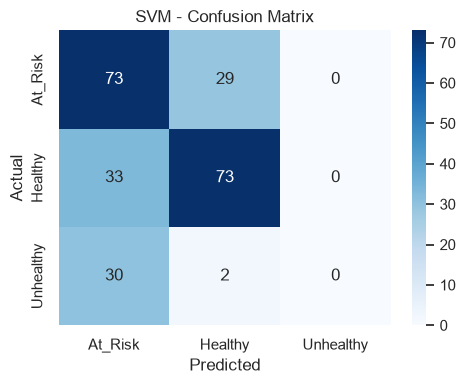


===== Random Forest =====


,Accuracy,Precision,Recall,F1-Score
Random Forest,0.641667,0.64707,0.641667,0.637537


              precision    recall  f1-score   support

     At_Risk       0.57      0.67      0.61       102
     Healthy       0.74      0.71      0.72       106
   Unhealthy       0.61      0.34      0.44        32

    accuracy                           0.64       240
   macro avg       0.64      0.57      0.59       240
weighted avg       0.65      0.64      0.64       240



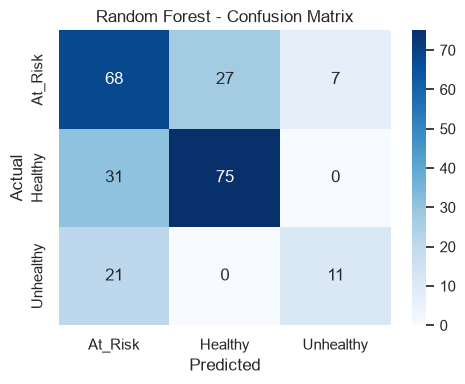


===== Ensemble =====


,Accuracy,Precision,Recall,F1-Score
Ensemble,0.65,0.659308,0.65,0.635834


              precision    recall  f1-score   support

     At_Risk       0.58      0.69      0.63       102
     Healthy       0.72      0.75      0.73       106
   Unhealthy       0.70      0.22      0.33        32

    accuracy                           0.65       240
   macro avg       0.67      0.55      0.57       240
weighted avg       0.66      0.65      0.64       240



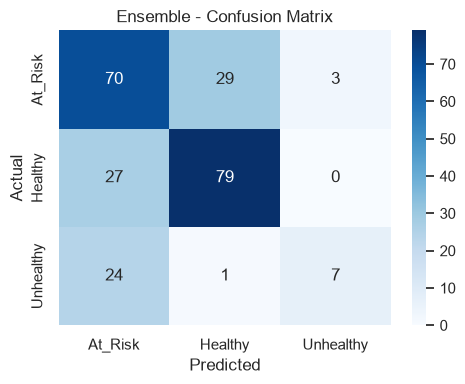

,Model,Accuracy,Precision,Recall,F1-Score
1,Random Forest,0.641667,0.647070,0.641667,0.637537
2,Ensemble,0.650000,0.659308,0.650000,0.635834
0,SVM,0.608333,0.538141,0.608333,0.567778


In [11]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

def calculate_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_true, y_pred, average="weighted", zero_division=0),
        "F1-Score": f1_score(y_true, y_pred, average="weighted", zero_division=0)
    }

models = {
    "SVM": (svm_pipeline, svm_pred),
    "Random Forest": (rf_pipeline, rf_pred),
    "Ensemble": (ensemble_pipeline, ensemble_pred)
}

initial_results = []
for name, (model, pred) in models.items():
    metrics = calculate_metrics(y_test, pred)
    initial_results.append({"Model": name, **metrics})
    print(f"\n===== {name} =====")
    display(pd.DataFrame([metrics], index=[name]))
    print(classification_report(y_test, pred, zero_division=0))

    cm = confusion_matrix(y_test, pred, labels=sorted(y.unique()))
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=sorted(y.unique()), yticklabels=sorted(y.unique()))
    plt.title(f"{name} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()

initial_results_df = pd.DataFrame(initial_results).sort_values("F1-Score", ascending=False)
display(initial_results_df)

### مرحله ۱۲ — Hyperparameter Tuning 

با `RandomizedSearchCV` پارامترهای SVM و Random Forest را فقط با Training Set و Cross-Validation جست‌وجو می‌کنیم.

In [12]:
from sklearn.model_selection import RandomizedSearchCV

svm_params = {
    "model__C": [0.1, 1, 10, 50],
    "model__gamma": ["scale", "auto", 0.01, 0.1],
    "model__kernel": ["rbf", "linear"],
    "model__class_weight": [None, "balanced"]
}
svm_search = RandomizedSearchCV(
    svm_pipeline,
    param_distributions=svm_params,
    n_iter=10,
    cv=5,
    scoring="f1_weighted",
    random_state=RANDOM_STATE,
    n_jobs=-1
)
svm_search.fit(X_train, y_train)
best_svm = svm_search.best_estimator_
best_svm_pred = best_svm.predict(X_test)

print("SVM بهترین پارامترها:")
print(svm_search.best_params_)
print("Best CV weighted F1:", round(svm_search.best_score_, 4))

SVM بهترین پارامترها:
{'model__kernel': 'rbf', 'model__gamma': 0.01, 'model__class_weight': None, 'model__C': 10}
Best CV weighted F1: 0.6025


In [13]:
rf_params = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None, 10, 20, 30],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2"],
    "model__class_weight": [None, "balanced"]
}
rf_search = RandomizedSearchCV(
    rf_pipeline,
    param_distributions=rf_params,
    n_iter=12,
    cv=5,
    scoring="f1_weighted",
    random_state=RANDOM_STATE,
    n_jobs=-1
)
rf_search.fit(X_train, y_train)
best_rf = rf_search.best_estimator_
best_rf_pred = best_rf.predict(X_test)

print("Random Forest بهترین پارامترها:")
print(rf_search.best_params_)
print("Best CV weighted F1:", round(rf_search.best_score_, 4))

Random Forest بهترین پارامترها:
{'model__n_estimators': 300, 'model__min_samples_split': 5, 'model__min_samples_leaf': 2, 'model__max_features': 'sqrt', 'model__max_depth': 30, 'model__class_weight': 'balanced'}
Best CV weighted F1: 0.6725


### مرحله ۱۳ — ارزیابی مدل‌های بهینه‌شده 
نتایج مدل‌های قبل و بعد از تنظیم پارامترها را روی Test Set مقایسه می‌کنیم.

,Model,Accuracy,Precision,Recall,F1-Score
3,Random Forest - After Tuning,0.683333,0.689204,0.683333,0.683813
2,Random Forest - Before Tuning,0.641667,0.647070,0.641667,0.637537
4,Ensemble,0.650000,0.659308,0.650000,0.635834
1,SVM - After Tuning,0.600000,0.600635,0.600000,0.591857
0,SVM - Before Tuning,0.608333,0.538141,0.608333,0.567778


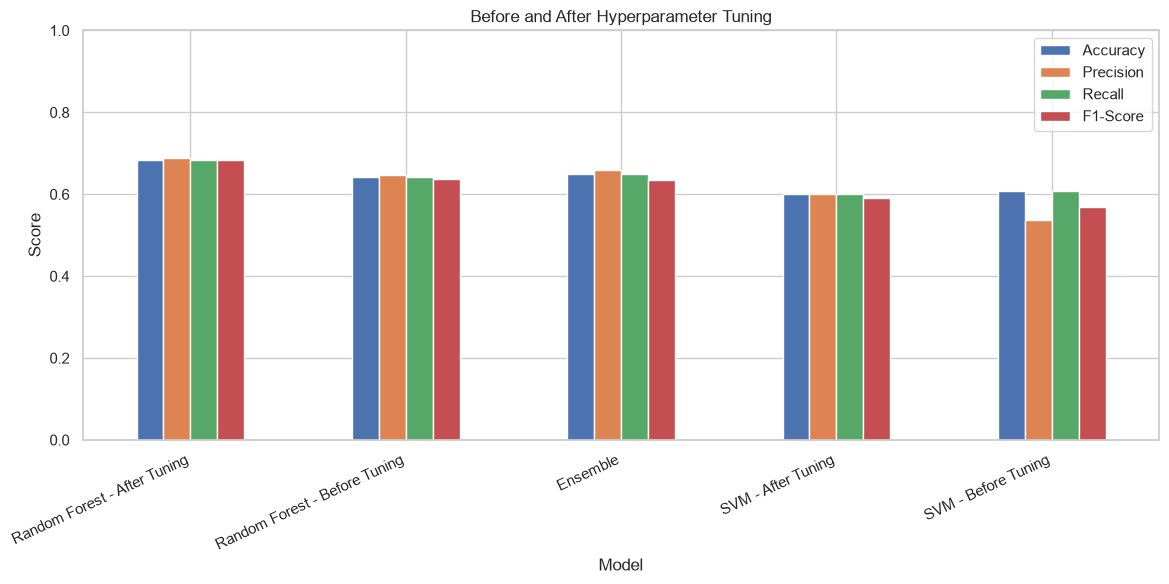

In [14]:
tuned_results = []
for name, pred in [
    ("SVM - Before Tuning", svm_pred),
    ("SVM - After Tuning", best_svm_pred),
    ("Random Forest - Before Tuning", rf_pred),
    ("Random Forest - After Tuning", best_rf_pred),
    ("Ensemble", ensemble_pred)
]:
    tuned_results.append({"Model": name, **calculate_metrics(y_test, pred)})

tuned_results_df = pd.DataFrame(tuned_results).sort_values("F1-Score", ascending=False)
display(tuned_results_df)

tuned_results_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1-Score"]].plot(
    kind="bar", figsize=(12, 6)
)
plt.title("Before and After Hyperparameter Tuning")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

### مرحله ۱۴ — Feature Importance 
اهمیت ویژگی‌ها را از Random Forest بهینه‌شده استخراج می‌کنیم.

,Feature,Importance
0,num__Temperature_C,0.122990
1,num__Humidity_pct,0.094096
5,num__CO2_ppm,0.079466
3,num__Soil_pH,0.079205
4,num__LightHours,0.076178
10,num__Temperature_Humidity,0.074509
2,num__SoilMoisture_pct,0.072573
6,num__Nitrogen_mgkg,0.058934
11,num__Moisture_Watering,0.051731
8,num__LeafTemperature_C,0.046034


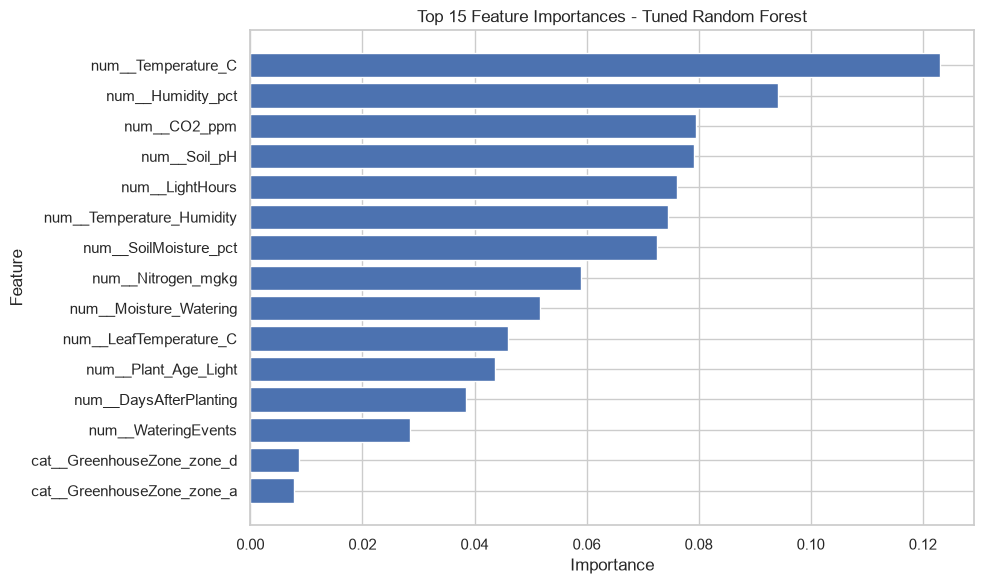

In [15]:
rf_preprocessor_fitted = best_rf.named_steps["preprocessor"]
rf_model_fitted = best_rf.named_steps["model"]
feature_names = rf_preprocessor_fitted.get_feature_names_out()
importance = rf_model_fitted.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values("Importance", ascending=False)

display(feature_importance.head(15))

# Matplotlib horizontal bar chart (avoids seaborn version compatibility issues)
plot_data = feature_importance.head(15).sort_values("Importance", ascending=True)
plt.figure(figsize=(10, 6))
plt.barh(plot_data["Feature"], plot_data["Importance"])
plt.title("Top 15 Feature Importances - Tuned Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## بخش دوم — شبکه‌های عصبی
### مرحله ۱۵ — آماده‌سازی داده برای شبکه عصبی 

یک نسخه جدا از Preprocessor را فقط روی Training Set آموزش می‌دهیم. سپس برچسب‌های هدف به عدد تبدیل می‌شوند.

In [16]:
from sklearn.base import clone
from sklearn.preprocessing import LabelEncoder

nn_preprocessor = clone(preprocessor)
X_train_nn = nn_preprocessor.fit_transform(X_train)
X_test_nn = nn_preprocessor.transform(X_test)

# Keras ورودی dense را به‌راحتی می‌پذیرد؛ اگر خروجی sparse باشد آن را تبدیل می‌کنیم.
if hasattr(X_train_nn, "toarray"):
    X_train_nn = X_train_nn.toarray()
if hasattr(X_test_nn, "toarray"):
    X_test_nn = X_test_nn.toarray()

label_encoder = LabelEncoder()
y_train_nn = label_encoder.fit_transform(y_train)
y_test_nn = label_encoder.transform(y_test)

print("شکل داده آموزش NN:", X_train_nn.shape)
print("شکل داده آزمون NN:", X_test_nn.shape)
print("ترتیب کلاس‌ها:", list(label_encoder.classes_))

شکل داده آموزش NN: (960, 34)
شکل داده آزمون NN: (240, 34)
ترتیب کلاس‌ها: ['At_Risk', 'Healthy', 'Unhealthy']


### مرحله ۱۶ — ایجاد اولین شبکه عصبی با Keras 
### مرحله ۱۷ — آزمایش Activation Functions 
### مرحله ۱۸ — آزمایش Batch Size و Epoch 

دو تنظیم را مقایسه می‌کنیم: `relu` با Batch Size برابر 32 و 30 Epoch، و `tanh` با Batch Size برابر 64 و 40 Epoch.

In [17]:
TF_AVAILABLE = False
try:
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import layers
    TF_AVAILABLE = True
    print("TensorFlow version:", tf.__version__)
except ImportError:
    print("TensorFlow نصب نیست. برای اجرای مراحل 16 تا 20، این دستور را در یک سلول جدا اجرا کنید:")
    print("%pip install tensorflow")

TensorFlow version: 2.21.0


In [18]:
nn_models = {}
nn_histories = {}
nn_test_predictions = {}
nn_test_probabilities = {}

if TF_AVAILABLE:
    def build_nn(input_dim, number_of_classes, activation="relu"):
        model = keras.Sequential([
            layers.Input(shape=(input_dim,)),
            layers.Dense(64, activation=activation),
            layers.Dropout(0.2),
            layers.Dense(32, activation=activation),
            layers.Dense(number_of_classes, activation="softmax")
        ])
        model.compile(
            optimizer="adam",
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"]
        )
        return model

    nn_configs = [
        {"name": "NN_ReLU_BS32_E30", "activation": "relu", "batch_size": 32, "epochs": 30},
        {"name": "NN_Tanh_BS64_E40", "activation": "tanh", "batch_size": 64, "epochs": 40}
    ]

    for config in nn_configs:
        print("\nTraining:", config["name"])
        model = build_nn(
            input_dim=X_train_nn.shape[1],
            number_of_classes=len(label_encoder.classes_),
            activation=config["activation"]
        )
        history = model.fit(
            X_train_nn,
            y_train_nn,
            validation_split=0.2,
            epochs=config["epochs"],
            batch_size=config["batch_size"],
            verbose=0
        )
        nn_models[config["name"]] = model
        nn_histories[config["name"]] = history
        probs = model.predict(X_test_nn, verbose=0)
        nn_test_probabilities[config["name"]] = probs
        nn_test_predictions[config["name"]] = label_encoder.inverse_transform(
            np.argmax(probs, axis=1)
        )
        print("پایان آموزش:", config["name"])
else:
    print("آموزش شبکه عصبی اجرا نشد، چون TensorFlow در محیط نصب نیست.")


Training: NN_ReLU_BS32_E30
پایان آموزش: NN_ReLU_BS32_E30

Training: NN_Tanh_BS64_E40
پایان آموزش: NN_Tanh_BS64_E40


نمودارهای Accuracy آموزش و اعتبارسنجی برای هر دو تنظیم:

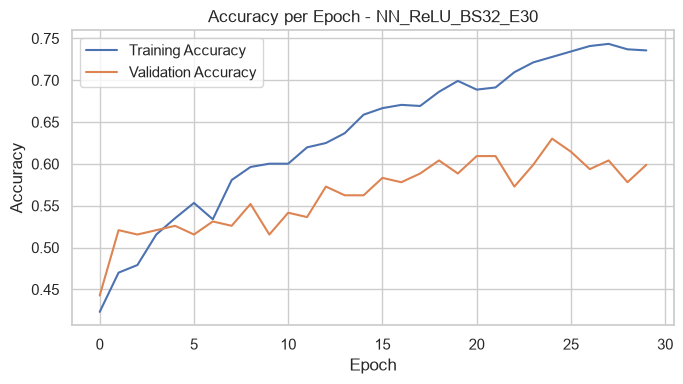

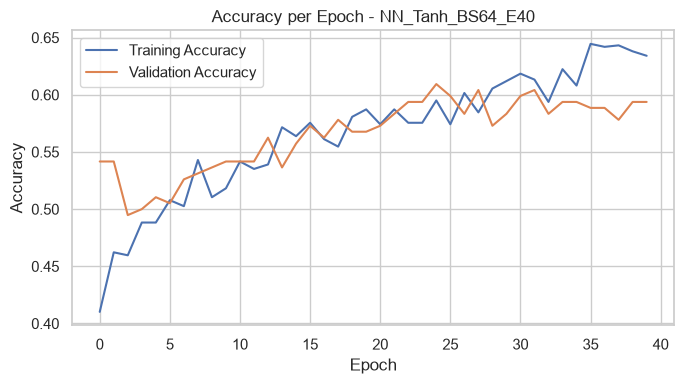

In [19]:
if TF_AVAILABLE and nn_histories:
    for name, history in nn_histories.items():
        plt.figure(figsize=(7, 4))
        plt.plot(history.history["accuracy"], label="Training Accuracy")
        plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
        plt.title(f"Accuracy per Epoch - {name}")
        plt.xlabel("Epoch")
        plt.ylabel("Accuracy")
        plt.legend()
        plt.tight_layout()
        plt.show()
else:
    print("پس از نصب TensorFlow و اجرای سلول آموزش، نمودارها نمایش داده می‌شوند.")

### مرحله ۱۹ — ارزیابی شبکه عصبی 
مدلی را که بالاترین Validation Accuracy را داشته انتخاب می‌کنیم؛ سپس معیارهای Test را گزارش می‌کنیم.

Neural Network منتخب: NN_ReLU_BS32_E30


,Accuracy,Precision,Recall,F1-Score
NN_ReLU_BS32_E30,0.55,0.544053,0.55,0.53696


              precision    recall  f1-score   support

     At_Risk       0.51      0.47      0.49       102
     Healthy       0.58      0.72      0.64       106
   Unhealthy       0.53      0.25      0.34        32

    accuracy                           0.55       240
   macro avg       0.54      0.48      0.49       240
weighted avg       0.54      0.55      0.54       240



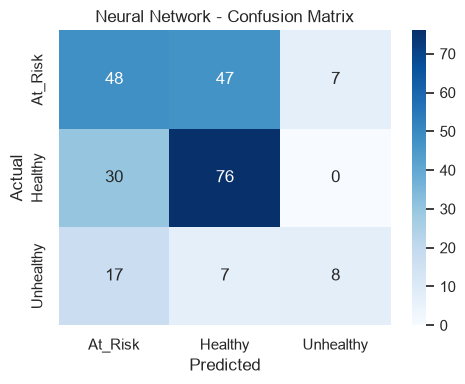

In [20]:
best_nn = None
best_nn_name = None
nn_pred = None
nn_cm = None
nn_metrics = None

if TF_AVAILABLE and nn_histories:
    best_nn_name = max(
        nn_histories,
        key=lambda name: max(nn_histories[name].history["val_accuracy"])
    )
    best_nn = nn_models[best_nn_name]
    nn_pred = nn_test_predictions[best_nn_name]
    nn_metrics = calculate_metrics(y_test, nn_pred)

    print("Neural Network منتخب:", best_nn_name)
    display(pd.DataFrame([nn_metrics], index=[best_nn_name]))
    print(classification_report(y_test, nn_pred, zero_division=0))

    nn_cm = confusion_matrix(y_test, nn_pred, labels=label_encoder.classes_)
    plt.figure(figsize=(5, 4))
    sns.heatmap(
        nn_cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_
    )
    plt.title("Neural Network - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()
else:
    print("ارزیابی NN تا زمان نصب TensorFlow در دسترس نیست.")

### مرحله ۲۰ — مقایسه مدل‌های Machine Learning و Neural Network 

,Model,Accuracy,Precision,Recall,F1-Score
0,Random Forest (Tuned),0.683333,0.689204,0.683333,0.683813
1,Ensemble,0.650000,0.659308,0.650000,0.635834
2,SVM (Tuned),0.600000,0.600635,0.600000,0.591857
3,NN_ReLU_BS32_E30,0.550000,0.544053,0.550000,0.536960


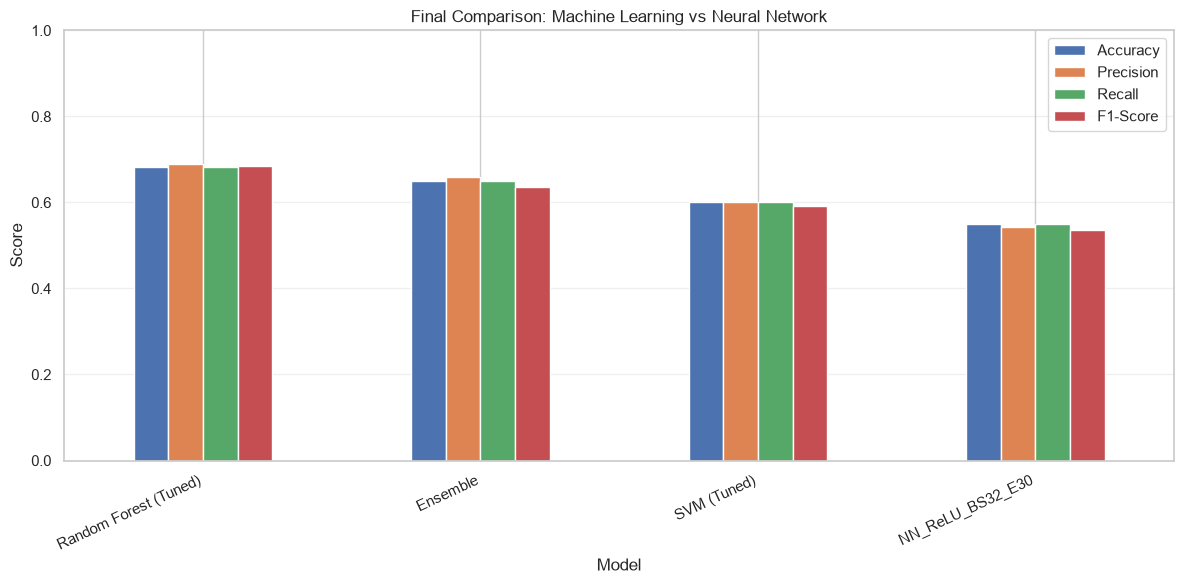

In [21]:
final_predictions = {
    "SVM (Tuned)": best_svm_pred,
    "Random Forest (Tuned)": best_rf_pred,
    "Ensemble": ensemble_pred
}
if nn_pred is not None:
    final_predictions[best_nn_name] = nn_pred

final_results = []
for name, pred in final_predictions.items():
    final_results.append({"Model": name, **calculate_metrics(y_test, pred)})

final_results_df = pd.DataFrame(final_results).sort_values(
    by="F1-Score", ascending=False
).reset_index(drop=True)

display(final_results_df)

final_results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
].plot(kind="bar", figsize=(12, 6))
plt.title("Final Comparison: Machine Learning vs Neural Network")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

##  بخش سوم — YOLO و تشخیص اشیا
### مرحله ۲۱ — آماده‌سازی YOLO 

برای این مرحله باید پکیج `ultralytics` نصب باشد و در اولین اجرا ممکن است دانلود وزن‌های آماده به اینترنت نیاز داشته باشد.

In [22]:
YOLO_AVAILABLE = False
yolo_model = None
try:
    from ultralytics import YOLO
    YOLO_AVAILABLE = True
    print("Ultralytics آماده است.")
except ImportError:
    print("Ultralytics نصب نیست. در صورت دسترسی به اینترنت، این دستور را اجرا کنید:")
    print("%pip install ultralytics")

Ultralytics آماده است.


In [23]:
if YOLO_AVAILABLE:
    try:
        yolo_model = YOLO("yolo11n.pt")
        print("YOLO model loaded successfully.")
    except Exception as e:
        print("مدل YOLO بارگذاری نشد. احتمالاً دانلود وزن‌ها یا اتصال اینترنت مشکل دارد.")
        print("جزئیات:", str(e)[:500])
        yolo_model = None
else:
    print("برای اجرای YOLO ابتدا ultralytics را نصب کنید.")

YOLO model loaded successfully.


### مرحله ۲۲ — اجرای Object Detection با YOLO 

تصویر `plant.jpg` را کنار Notebook قرار دهید. خروجی‌ها شامل Class، Confidence و Bounding Box هستند و تصویر تشخیص‌داده‌شده ذخیره می‌شود.

In [24]:
image_path = "plant.jpg"
image_results = None

if yolo_model is not None and os.path.exists(image_path):
    try:
        image_results = yolo_model.predict(
            source=image_path,
            conf=0.25,
            save=True
        )
        for result in image_results:
            print("Detected objects:")
            for box in result.boxes:
                class_id = int(box.cls[0])
                class_name = yolo_model.names[class_id]
                confidence = float(box.conf[0])
                coordinates = box.xyxy[0].tolist()
                print("Class:", class_name)
                print("Confidence:", round(confidence, 3))
                print("Bounding Box (x1, y1, x2, y2):", [round(v, 2) for v in coordinates])
                print("-" * 25)
        print("تصویر خروجی در پوشه runs/detect ذخیره می‌شود.")
    except Exception as e:
        print("اجرای YOLO روی تصویر با خطا مواجه شد:", str(e)[:500])
else:
    print("برای اجرای این مرحله، YOLO را آماده کنید و فایل plant.jpg را کنار Notebook قرار دهید.")

برای اجرای این مرحله، YOLO را آماده کنید و فایل plant.jpg را کنار Notebook قرار دهید.


### مرحله ۲۳ — اجرای YOLO روی تصویر یا ویدئوی جدید 

این مرحله اختیاری است و به فایل `greenhouse.mp4` نیاز دارد. اگر ویدئو موجود نباشد، Notebook بدون خطا ادامه می‌دهد.

In [25]:
video_path = "greenhouse.mp4"

if yolo_model is not None and os.path.exists(video_path):
    try:
        video_results = yolo_model.predict(
            source=video_path,
            conf=0.25,
            save=True
        )
        print("Video detection completed. خروجی در پوشه runs/detect ذخیره می‌شود.")
    except Exception as e:
        print("اجرای YOLO روی ویدئو با خطا مواجه شد:", str(e)[:500])
else:
    print("برای اجرای ویدئو، فایل greenhouse.mp4 را کنار Notebook قرار دهید.")

برای اجرای ویدئو، فایل greenhouse.mp4 را کنار Notebook قرار دهید.


##  بخش چهارم — پیش‌بینی نمونه جدید
### مرحله ۲۴ — پیش‌بینی سلامت یک گیاه جدید 

نمونه زیر از ساختار واقعی ویژگی‌ها کپی می‌شود، سپس چند مقدار عددی آن تغییر می‌کند. این کار کمک می‌کند همه ستون‌های دسته‌ای موردنیاز هم در نمونه باقی بمانند.

In [26]:
new_plant = X.iloc[[0]].copy()

sample_values = {
    "Temperature_C": 25,
    "Humidity_pct": 60,
    "SoilMoisture_pct": 45,
    "Soil_pH": 6.5,
    "LightHours": 10,
    "CO2_ppm": 450,
    "Nitrogen_mgkg": 140,
    "WateringEvents": 2,
    "LeafTemperature_C": 24,
    "DaysAfterPlanting": 30
}
for col, value in sample_values.items():
    if col in new_plant.columns:
        new_plant.loc[:, col] = value

# به‌روزرسانی Feature Engineering مطابق همان فرمول‌های بالا
new_plant["Temperature_Humidity"] = (
    new_plant["Temperature_C"] * new_plant["Humidity_pct"]
)
new_plant["Moisture_Watering"] = (
    new_plant["SoilMoisture_pct"] * new_plant["WateringEvents"]
)
new_plant["Plant_Age_Light"] = (
    new_plant["DaysAfterPlanting"] * new_plant["LightHours"]
)

print("SVM Prediction:", best_svm.predict(new_plant)[0])
print("Random Forest Prediction:", best_rf.predict(new_plant)[0])
print("Ensemble Prediction:", ensemble_pipeline.predict(new_plant)[0])

if best_nn is not None:
    new_plant_nn = nn_preprocessor.transform(new_plant)
    if hasattr(new_plant_nn, "toarray"):
        new_plant_nn = new_plant_nn.toarray()

    nn_result = best_nn.predict(new_plant_nn, verbose=0)
    nn_class_index = np.argmax(nn_result, axis=1)
    nn_prediction = label_encoder.inverse_transform(nn_class_index)[0]
    print("Neural Network Prediction:", nn_prediction)

    nn_probabilities = nn_result[0]
    probability_table = pd.DataFrame({
        "PlantHealth": label_encoder.classes_,
        "Probability": nn_probabilities
    }).sort_values("Probability", ascending=False)
    display(probability_table)
else:
    print("پیش‌بینی Neural Network پس از نصب TensorFlow و آموزش مدل در دسترس است.")

SVM Prediction: Healthy
Random Forest Prediction: Healthy
Ensemble Prediction: Healthy
Neural Network Prediction: Healthy


,PlantHealth,Probability
1,Healthy,0.884682
0,At_Risk,0.096864
2,Unhealthy,0.018453


## نتیجه‌گیری نهایی

سلول بعدی خلاصه‌ای بر اساس نتایج واقعی همین اجرا می‌سازد. برای گزارش نهایی، درباره کیفیت داده‌ها، تصمیم‌های پاک‌سازی، ویژگی‌های جدید، عملکرد مدل‌ها، تنظیم پارامترها، اثر Batch Size/Epoch و کاربرد YOLO توضیح دهید.

**محدودیت مهم:** اگر تصویر/ویدئو یا TensorFlow در محیط موجود نباشد، آن بخش اجرا نمی‌شود؛ پیام سلول مشخص می‌کند چه چیزی باقی مانده است. مدل YOLO آماده نیز به‌تنهایی وضعیت سلامت گیاه را تشخیص نمی‌دهد.

In [27]:
print(" SMART GREENHOUSE PROJECT SUMMARY")
print("=" * 50)
print("Rows after cleaning:", len(df_features))
print("Number of input features:", X.shape[1])
print("Target class counts:")
display(y.value_counts().to_frame("Count"))

print("\nModel comparison:")
display(final_results_df)

best_row = final_results_df.iloc[0]
print("Best model by weighted F1-Score:", best_row["Model"])
print("Accuracy:", round(best_row["Accuracy"], 4))
print("Precision:", round(best_row["Precision"], 4))
print("Recall:", round(best_row["Recall"], 4))
print("F1-Score:", round(best_row["F1-Score"], 4))

print("\nConclusion:")
print(
    "The dataset was cleaned by normalizing text values, removing duplicates, "
    "and marking values outside selected plausible ranges as missing. Missing "
    "values were imputed within preprocessing pipelines. Three engineered "
    "features were added. SVM, Random Forest, and a Voting Ensemble were trained "
    "and compared; SVM and Random Forest were also tuned with RandomizedSearchCV. "
    "The model with the highest weighted F1-Score in the final table is the best "
    "according to that metric on this test split."
)
if best_nn is None:
    print("Neural Network: not evaluated in this run because TensorFlow was unavailable.")
else:
    print("Neural Network selected:", best_nn_name)
if yolo_model is None:
    print("YOLO: not loaded in this run.")
elif not os.path.exists("plant.jpg"):
    print("YOLO: loaded, but no plant.jpg was provided for image detection.")
if not os.path.exists("greenhouse.mp4"):
    print("YOLO video: skipped because greenhouse.mp4 was not provided.")

 SMART GREENHOUSE PROJECT SUMMARY
Rows after cleaning: 1200
Number of input features: 19
Target class counts:


,Count
PlantHealth,
Healthy,530
At_Risk,512
Unhealthy,158



Model comparison:


,Model,Accuracy,Precision,Recall,F1-Score
0,Random Forest (Tuned),0.683333,0.689204,0.683333,0.683813
1,Ensemble,0.650000,0.659308,0.650000,0.635834
2,SVM (Tuned),0.600000,0.600635,0.600000,0.591857
3,NN_ReLU_BS32_E30,0.550000,0.544053,0.550000,0.536960


Best model by weighted F1-Score: Random Forest (Tuned)
Accuracy: 0.6833
Precision: 0.6892
Recall: 0.6833
F1-Score: 0.6838

Conclusion:
The dataset was cleaned by normalizing text values, removing duplicates, and marking values outside selected plausible ranges as missing. Missing values were imputed within preprocessing pipelines. Three engineered features were added. SVM, Random Forest, and a Voting Ensemble were trained and compared; SVM and Random Forest were also tuned with RandomizedSearchCV. The model with the highest weighted F1-Score in the final table is the best according to that metric on this test split.
Neural Network selected: NN_ReLU_BS32_E30
YOLO: loaded, but no plant.jpg was provided for image detection.
YOLO video: skipped because greenhouse.mp4 was not provided.
